In [3]:
import os

In [6]:
os.makedirs("data/raw", exist_ok=True)

In [8]:
import os
import time
import requests
from bs4 import BeautifulSoup
import pandas as pd

BASE_URL = "https://books.toscrape.com/catalogue/page-{}.html"
RATING_MAP = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}

def scrape_page(page_num):
    url = BASE_URL.format(page_num)
    response = requests.get(url, timeout=10)
    if response.status_code != 200:
        return []

    soup = BeautifulSoup(response.text, "html.parser")
    books = []

    for item in soup.find_all("article", class_="product_pod"):
        title = item.h3.a["title"]
        price = item.find("p", class_="price_color").text
        rating_word = item.find("p", class_="star-rating")["class"][1]
        availability = item.find("p", class_="instock availability").text.strip()
        link = item.h3.a["href"]

        books.append({
            "title": title,
            "price": price,
            "rating": RATING_MAP[rating_word],
            "availability": availability,
            "link": link,
        })
    return books

def main():
    all_books = []
    for page in range(1, 51):
        print(f"Scraping page {page}...")
        all_books.extend(scrape_page(page))
        time.sleep(1)

    df = pd.DataFrame(all_books)
    os.makedirs("data/raw", exist_ok=True)
    df.to_csv("data/raw/books_raw.csv", index=False)
    print(f"Done! Scraped {len(df)} books.")

if __name__ == "__main__":
    main()

Scraping page 1...
Scraping page 2...
Scraping page 3...
Scraping page 4...
Scraping page 5...
Scraping page 6...
Scraping page 7...
Scraping page 8...
Scraping page 9...
Scraping page 10...
Scraping page 11...
Scraping page 12...
Scraping page 13...
Scraping page 14...
Scraping page 15...
Scraping page 16...
Scraping page 17...
Scraping page 18...
Scraping page 19...
Scraping page 20...
Scraping page 21...
Scraping page 22...
Scraping page 23...
Scraping page 24...
Scraping page 25...
Scraping page 26...
Scraping page 27...
Scraping page 28...
Scraping page 29...
Scraping page 30...
Scraping page 31...
Scraping page 32...
Scraping page 33...
Scraping page 34...
Scraping page 35...
Scraping page 36...
Scraping page 37...
Scraping page 38...
Scraping page 39...
Scraping page 40...
Scraping page 41...
Scraping page 42...
Scraping page 43...
Scraping page 44...
Scraping page 45...
Scraping page 46...
Scraping page 47...
Scraping page 48...
Scraping page 49...
Scraping page 50...
Done! Scr

In [9]:
import pandas as pd
df = pd.read_csv("data/raw/books_raw.csv")
print(df.shape)
df.head()

(1000, 5)


,title,price,rating,availability,link
0,A Light in the Attic,Â£51.77,3,In stock,a-light-in-the-attic_1000/index.html
1,Tipping the Velvet,Â£53.74,1,In stock,tipping-the-velvet_999/index.html
2,Soumission,Â£50.10,1,In stock,soumission_998/index.html
3,Sharp Objects,Â£47.82,4,In stock,sharp-objects_997/index.html
4,Sapiens: A Brief History of Humankind,Â£54.23,5,In stock,sapiens-a-brief-history-of-humankind_996/index...


In [10]:
import pandas as pd
import os

df = pd.read_csv("data/raw/books_raw.csv")

df.head()          # first 5 rows
df.info()          # column names, data types, non-null counts
df.isnull().sum()  # missing values per column
df.duplicated().sum()  # duplicate rows
df["price"].head() # look closely at the price format


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   title         1000 non-null   object
 1   price         1000 non-null   object
 2   rating        1000 non-null   int64 
 3   availability  1000 non-null   object
 4   link          1000 non-null   object
dtypes: int64(1), object(4)
memory usage: 39.2+ KB


0    Â£51.77
1    Â£53.74
2    Â£50.10
3    Â£47.82
4    Â£54.23
Name: price, dtype: object

In [11]:
# Work on a copy so the raw data stays safe
df_clean = df.copy()

# 1. Price: remove currency symbols and convert text to a number
df_clean["price"] = (
    df_clean["price"]
    .str.replace("Â", "", regex=False)
    .str.replace("£", "", regex=False)
    .astype(float)
)

# 2. Availability: turn the text into a simple True/False column
df_clean["in_stock"] = df_clean["availability"].str.contains("In stock")

# 3. Remove duplicates
before = len(df_clean)
df_clean = df_clean.drop_duplicates()
print(f"Removed {before - len(df_clean)} duplicate rows")

# 4. Drop the column we no longer need
df_clean = df_clean.drop(columns=["availability"])

Removed 0 duplicate rows


In [12]:
df_clean.info()
df_clean.describe()
df_clean.head()

os.makedirs("data/cleaned", exist_ok=True)
df_clean.to_csv("data/cleaned/books_cleaned.csv",index=False)
print("Saved cleand data:",df_clean.shape)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   title     1000 non-null   object 
 1   price     1000 non-null   float64
 2   rating    1000 non-null   int64  
 3   link      1000 non-null   object 
 4   in_stock  1000 non-null   bool   
dtypes: bool(1), float64(1), int64(1), object(2)
memory usage: 32.4+ KB
Saved cleand data: (1000, 5)


In [13]:
df_clean["price"].describe()

count    1000.00000
mean       35.07035
std        14.44669
min        10.00000
25%        22.10750
50%        35.98000
75%        47.45750
max        59.99000
Name: price, dtype: float64

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

df = pd.read_csv("data/cleaned/books_cleaned.csv")
os.makedirs("images", exist_ok=True)
sns.set_style("whitegrid")

print(df.shape)
df.head()

(1000, 5)


,title,price,rating,link,in_stock
0,A Light in the Attic,51.77,3,a-light-in-the-attic_1000/index.html,True
1,Tipping the Velvet,53.74,1,tipping-the-velvet_999/index.html,True
2,Soumission,50.10,1,soumission_998/index.html,True
3,Sharp Objects,47.82,4,sharp-objects_997/index.html,True
4,Sapiens: A Brief History of Humankind,54.23,5,sapiens-a-brief-history-of-humankind_996/index...,True


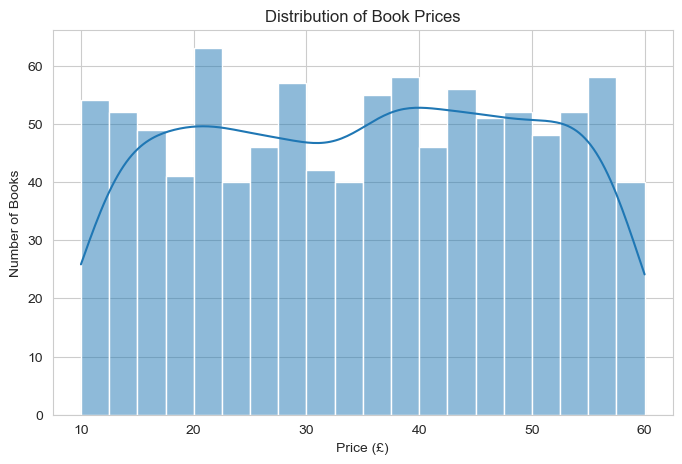

count    1000.00000
mean       35.07035
std        14.44669
min        10.00000
25%        22.10750
50%        35.98000
75%        47.45750
max        59.99000
Name: price, dtype: float64


In [15]:
plt.figure(figsize=(8, 5))
sns.histplot(df["price"], bins=20, kde=True)
plt.title("Distribution of Book Prices")
plt.xlabel("Price (£)")
plt.ylabel("Number of Books")
plt.savefig("images/price_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

print(df["price"].describe())

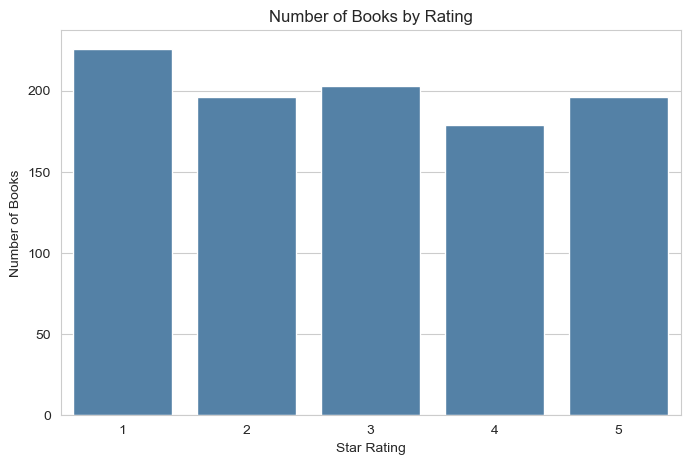

37.5% of books are rated 4 or 5 stars


In [16]:
rating_counts = df["rating"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
sns.barplot(x=rating_counts.index, y=rating_counts.values, color="steelblue")
plt.title("Number of Books by Rating")
plt.xlabel("Star Rating")
plt.ylabel("Number of Books")
plt.savefig("images/rating_counts.png", dpi=150, bbox_inches="tight")
plt.show()

high_rated = (df["rating"] >= 4).mean() * 100
print(f"{high_rated:.1f}% of books are rated 4 or 5 stars")

rating
1    34.56
2    34.81
3    34.69
4    36.09
5    35.37
Name: price, dtype: float64


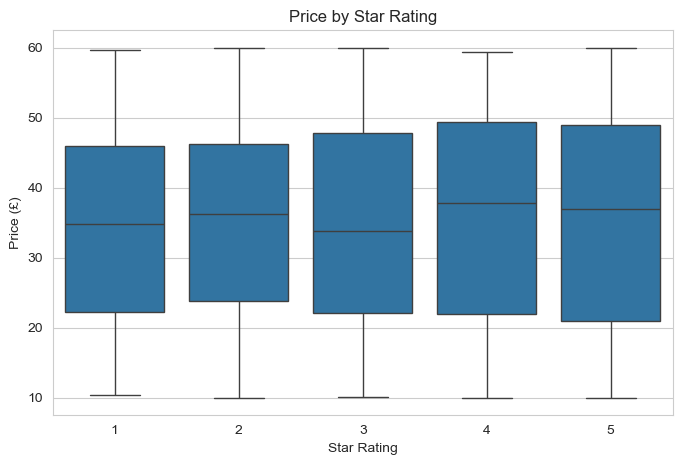

Correlation (rating vs price): 0.028


In [17]:
avg_price = df.groupby("rating")["price"].mean().round(2)
print(avg_price)

plt.figure(figsize=(8, 5))
sns.boxplot(x="rating", y="price", data=df)
plt.title("Price by Star Rating")
plt.xlabel("Star Rating")
plt.ylabel("Price (£)")
plt.savefig("images/price_by_rating.png", dpi=150, bbox_inches="tight")
plt.show()

# Correlation: a number between -1 and 1
print("Correlation (rating vs price):", round(df["rating"].corr(df["price"]), 3))

In [18]:
Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)
IQR = Q3 - Q1
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR

outliers = df[(df["price"] < lower) | (df["price"] > upper)]
print(f"Outlier range: below £{lower:.2f} or above £{upper:.2f}")
print(f"Number of outliers: {len(outliers)}")
outliers[["title", "price"]].head()

Outlier range: below £-15.92 or above £85.48
Number of outliers: 0


,title,price


In [19]:
stock_counts = df["in_stock"].value_counts()
print(stock_counts)
print(f"{df['in_stock'].mean() * 100:.1f}% of books are in stock")

in_stock
True    1000
Name: count, dtype: int64
100.0% of books are in stock
